# Lab Day 10 trên Kaggle (2 × T4): Qwen3-VL-4B QLoRA
Đoàn Duy Bách · MSSV 2A202602515

Cùng mã `lab/` và cùng cấu hình `configs/` như `lab_day10.ipynb` (bản Colab); chỉ khác là chạy **hai thí nghiệm song song trên hai GPU T4**.

**Cài đặt notebook (cột phải):** Accelerator = **GPU T4 x2**, Internet = **On** (cần xác minh số điện thoại).
Rồi bấm **Save Version → Save & Run All (Commit)**: chạy nền, tắt trình duyệt/tắt máy vẫn chạy.
Xong (~2,5–3 giờ): mở version vừa chạy → tab **Output** → tải `report.zip`.

| Hàng đợi | GPU 0 | GPU 1 |
|---|---|---|
| Đợt 1 | E1 → E3 | E0 → E2 |
| Đợt 2 (sau khi biết `BEST`) | E4 (`coord_scale=pixel`) | E5 GRPO (tuỳ chọn) |

In [4]:
import os, subprocess, time, json
REPO_URL = 'https://github.com/DuyBach2003/K4-Track-4-Day10-VisionLanguageModel.git'
REPO = '/kaggle/working/lab10'
def sh(cmd): subprocess.run(cmd, shell=True, check=True)
sh('nvidia-smi -L')
if not os.path.exists(REPO):
    sh(f'git clone -q {REPO_URL} {REPO}')
os.chdir(REPO)
sh('git pull -q')
sh('pip -q install -r requirements-colab.txt')
# torchao cũ cài sẵn làm peft 0.21.2 báo ImportError (cần ≥ 0.16); lab không dùng torchao.
sh('pip -q uninstall -y torchao || true')
sh('python -c "import torch, transformers, peft, trl, bitsandbytes; print(torch.__version__, transformers.__version__, peft.__version__, trl.__version__, bitsandbytes.__version__, torch.cuda.device_count(), \'GPU\')"')

GPU 0: Tesla T4 (UUID: GPU-96d53ee5-bc28-7253-d6cb-37914893c0bb)
GPU 1: Tesla T4 (UUID: GPU-ee2c03b0-5879-8d9e-1e11-46d69bf53ca8)


2.11.0+cu128 5.19.0 0.21.2 1.9.2 0.50.2 2 GPU


In [5]:
sh('python scripts/prepare_data.py --zip https://www.kaggle.com/api/v1/datasets/download/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes --work /kaggle/temp/dl')
sh('python -m pytest -q && python -m pytest -q lab/tests')
sh('python -m lab.viz data --out report/figures/data_samples.png')

dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}
...........................s.........................................    [100%]
68 passed, 1 skipped in 0.43s
..........................                                               [100%]
26 passed in 0.13s
wrote report/figures/data_samples.png


In [6]:
# Chạy các hàng đợi song song, mỗi hàng một GPU; log từng hàng ở work/logs/. Một thí nghiệm lỗi không chặn thí nghiệm sau.
os.makedirs('work/logs', exist_ok=True)

def exp(name, train_args=None, zero_shot=False):
    steps = []
    if train_args:
        steps.append(f'python -m lab.run train --name {name} {train_args}')
    steps.append(f'python -m lab.run predict --name {name}' + (' --zero-shot' if zero_shot else ''))
    steps.append(f'python -m lab.run score --name {name}')
    return ' && '.join(steps)

def run_queues(queues):
    procs = {}
    for gpu, (tag, jobs) in enumerate(queues):
        script = ' ; '.join(f'( {j} )' for j in jobs)
        if gpu:   # lệch giờ khởi động để hai tiến trình không cùng nạp model 4B vào RAM
            script = 'sleep 180 ; ' + script
        log = open(f'work/logs/{tag}.log', 'a')
        procs[tag] = subprocess.Popen(['bash', '-c', script], stdout=log, stderr=subprocess.STDOUT,
                                      env={**os.environ, 'CUDA_VISIBLE_DEVICES': str(gpu), 'PYTHONUNBUFFERED': '1'})
    t0 = time.time()
    while any(p.poll() is None for p in procs.values()):
        time.sleep(120)
        status = []
        for tag in procs:
            lines = [l for l in open(f'work/logs/{tag}.log', errors='ignore').read().splitlines()
                     if l.startswith(('step', '[', 'E', '{')) or 'ảnh, còn' in l or 'Error' in l]
            status.append(f'{tag}: {lines[-1][:110] if lines else "..."}')
        print(f'[{(time.time() - t0) / 60:5.1f} phút] ' + ' || '.join(status), flush=True)
    for tag in procs:
        print(f'--- {tag}: exit {procs[tag].returncode}')
        sh(f"grep -E '^(E[0-9]|   (pothole|crack|manhole))|Error|chạy tiếp|trainable_params' work/logs/{tag}.log | tail -30 || true")

run_queues([
    ('gpu0_e1_e3', [exp('e1', '--config configs/e1.yaml'), exp('e3', '--config configs/e3.yaml')]),
    ('gpu1_e0_e2', [exp('e0', zero_shot=True), exp('e2', '--config configs/e2.yaml')]),
])

[  2.0 phút] gpu0_e1_e3: step    1/300 loss=1.8799 lr=1.33e-05 gnorm=7.91 0.2 phút || gpu1_e0_e2: ...
[  4.0 phút] gpu0_e1_e3: step   10/300 loss=0.8008 lr=1.33e-04 gnorm=1.02 1.5 phút || gpu1_e0_e2: [e0] coord=norm1000 extra_tensors=0 n=311
[  6.0 phút] gpu0_e1_e3: step   30/300 loss=0.6613 lr=1.99e-04 gnorm=0.41 4.8 phút || gpu1_e0_e2: 80/311 ảnh, còn ~5.4 phút
[  8.0 phút] gpu0_e1_e3: step   40/300 loss=0.6184 lr=1.96e-04 gnorm=0.43 6.4 phút || gpu1_e0_e2: 80/311 ảnh, còn ~5.4 phút
[ 10.0 phút] gpu0_e1_e3: step   50/300 loss=0.6156 lr=1.93e-04 gnorm=0.48 8.0 phút || gpu1_e0_e2: 160/311 ảnh, còn ~5.0 phút
[ 12.0 phút] gpu0_e1_e3: step   60/300 loss=0.6262 lr=1.88e-04 gnorm=0.47 9.7 phút || gpu1_e0_e2: 240/311 ảnh, còn ~2.3 phút
[ 14.0 phút] gpu0_e1_e3: step   70/300 loss=0.6349 lr=1.82e-04 gnorm=0.44 11.3 phút || gpu1_e0_e2: 240/311 ảnh, còn ~2.3 phút
[ 16.0 phút] gpu0_e1_e3: step   90/300 loss=0.6291 lr=1.68e-04 gnorm=0.46 14.7 phút || gpu1_e0_e2: step    1/300 loss=1.8799 lr=1.33e-

In [7]:
f1 = {n: json.load(open(f'report/evidence/{n}.json'))['micro']['f1']
      for n in ('e1', 'e2', 'e3') if os.path.exists(f'report/evidence/{n}.json')}
BEST = max(f1, key=f1.get) if f1 else 'e1'
print({k: round(v, 3) for k, v in f1.items()}, '→ BEST =', BEST)
RUN_E5 = True    # đặt False nếu muốn bỏ E5 (tuỳ chọn, +10)
run_queues([
    ('gpu0_e4', [exp('e4_coord_scale_pixel', f'--config configs/{BEST}.yaml --set coord=pixel'),
                 f'python -m lab.run score --name e4_coord_scale_norm1000 --pred-from {BEST}']),
    ('gpu1_e5', [f'python -m lab.grpo --init {BEST} --name e5 --config configs/e5.yaml && ' + exp('e5')] if RUN_E5 else ['true']),
])

{'e1': 0.252, 'e2': 0.308, 'e3': 0.446} → BEST = e3
[  2.0 phút] gpu0_e4: step    1/300 loss=1.8252 lr=1.33e-05 gnorm=8.67 0.2 phút || gpu1_e5: ...
[  4.0 phút] gpu0_e4: step   10/300 loss=0.7445 lr=1.33e-04 gnorm=1.15 2.0 phút || gpu1_e5: ...
[  6.0 phút] gpu0_e4: step   20/300 loss=0.6637 lr=2.00e-04 gnorm=0.54 3.9 phút || gpu1_e5: [transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation confi
[  8.0 phút] gpu0_e4: step   30/300 loss=0.6507 lr=1.99e-04 gnorm=1.47 5.8 phút || gpu1_e5: {'loss': '0.1375', 'grad_norm': '0.4042', 'learning_rate': '4.583e-06', 'num_tokens': '1.111e+04', 'completion
[ 10.0 phút] gpu0_e4: step   50/300 loss=0.6435 lr=1.93e-04 gnorm=0.87 9.7 phút || gpu1_e5: {'loss': '0.08454', 'grad_norm': '0.5227', 'learning_rate': '4.25e-06', 'num_tokens': '1.841e+04', 'completion
[ 12.0 phút] gpu0_e4: step   60/300 loss=0.6324 lr=1.88e-04 gnorm=0.53 11.6 phút || gpu1_e5: {'loss': '0.3548', 'grad_norm': '0.6069', 'learning_ra

wrote report/figures/e0_examples.png
wrote report/figures/e1_examples.png
wrote report/figures/e2_examples.png
wrote report/figures/e3_examples.png
wrote report/figures/e4_coord_scale_pixel_examples.png
wrote report/figures/e5_examples.png
| Mã | Setup | Tham số huấn luyện | VRAM đỉnh (GB) | Phút | F1 | CI95 | FP/ảnh | F1 pothole | F1 crack | F1 manhole | parse_valid |
|---|---|---|---|---|---|---|---|---|---|---|---|
| E0 | zero-shot | 0 |  |  | 0.116 | 0.088–0.145 | 0.96 | 0.133 | 0.039 | 0.255 | 0.949 |
| E1 | LoRA LLM | 33.0M | 6.59 | 49.0 | 0.252 | 0.216–0.290 | 1.31 | 0.173 | 0.180 | 0.516 | 0.994 |
| E2 | + projector | 142.1M | 8.28 | 46.5 | 0.308 | 0.268–0.349 | 1.12 | 0.148 | 0.234 | 0.593 | 1.000 |
| E3 | + LoRA ViT | 148.4M | 8.46 | 57.8 | 0.446 | 0.405–0.487 | 0.86 | 0.303 | 0.376 | 0.697 | 1.000 |
| E4 | coord scale norm1000 | 148.4M | 8.46 | 57.8 | 0.446 | 0.405–0.487 | 0.86 | 0.303 | 0.376 | 0.697 | 1.000 |
| E4 | coord scale pixel | 148.4M | 8.45 | 57.8 | 0.407 | 0.367–

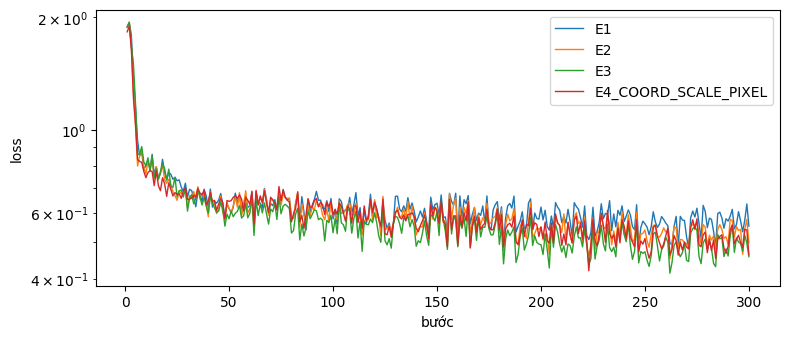

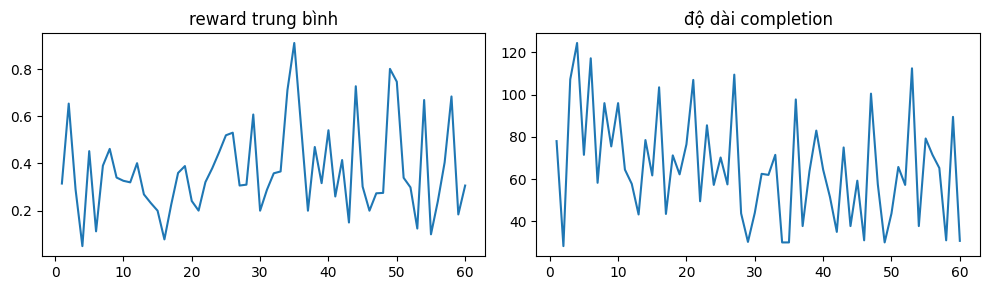

In [8]:
import matplotlib.pyplot as plt
from scripts.labcommon import read_jsonl
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in ('e1', 'e2', 'e3', 'e4_coord_scale_pixel'):
    p = f'work/{name}/train_log.jsonl'
    if os.path.exists(p):
        log = read_jsonl(p)
        ax.plot([r['step'] for r in log], [r['loss'] for r in log], label=name.upper(), lw=1)
ax.set_xlabel('bước'); ax.set_ylabel('loss'); ax.set_yscale('log'); ax.legend()
fig.tight_layout(); fig.savefig('report/figures/train_loss.png', dpi=120)
for name, coord in (('e0', 'norm1000'), ('e1', 'norm1000'), ('e2', 'norm1000'), ('e3', 'norm1000'),
                    ('e4_coord_scale_pixel', 'pixel'), ('e5', 'norm1000')):
    if os.path.exists(f'work/{name}_test.jsonl'):
        sh(f'python -m lab.viz pred --name {name} --coord {coord} --out report/figures/{name}_examples.png')
if os.path.exists('work/e5/grpo_log.jsonl'):
    log = read_jsonl('work/e5/grpo_log.jsonl')
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot([r['step'] for r in log], [r['reward'] for r in log]); ax[0].set_title('reward trung bình')
    ax[1].plot([r['step'] for r in log], [r['completions/mean_length'] for r in log]); ax[1].set_title('độ dài completion')
    fig.tight_layout(); fig.savefig('report/figures/e5_grpo.png', dpi=120)
sh('python -m lab.summarize')

In [9]:
# Đóng gói để tải về: report/ (bằng chứng + ảnh), log huấn luyện và dự đoán thô (không có trọng số).
sh('mkdir -p report/runs && for d in work/*/; do n=$(basename $d); [ -f $d/run.json ] && mkdir -p report/runs/$n && '
   'cp $d/run.json $d/*log.jsonl report/runs/$n/ 2>/dev/null; done; cp work/*_test.jsonl work/logs/*.log report/runs/ 2>/dev/null; true')
sh('cd /kaggle/working && rm -f report.zip && cd lab10 && zip -qr /kaggle/working/report.zip report')
sh('ls -la /kaggle/working/report.zip && unzip -l /kaggle/working/report.zip | tail -3')

-rw-r--r-- 1 root root 14714787 Oct 13 17:45 /kaggle/working/report.zip
        0  2026-10-13 14:18   report/evidence/.gitkeep
---------                     -------
 15261669                     46 files
